# Ames Housing — What Drives House Prices?

**Question:** Which features best explain the sale price of a home in Ames, Iowa, and how accurately can we predict it?

**Data:** 2,930 residential sales in Ames, Iowa, 2006–2010, with 82 variables per sale covering the lot, dwelling, basement, garage, location, condition, and sale details. Source: De Cock (2011), "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project", *Journal of Statistics Education*, 19(3) — the same dataset used in Kaggle's "House Prices: Advanced Regression Techniques" competition.

**Approach:** load and inspect → treat missing values explicitly → exploratory analysis → feature engineering → ANOVA tests of group differences → regression modelling (Linear, Ridge, Random Forest, XGBoost) with hyperparameter tuning → findings.

**Author:** Rabin Dhakal

## 1. Setup

In [1]:
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import Image, display

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from xgboost import XGBRegressor

import statsmodels.api as sm
from statsmodels.formula.api import ols

# Compatibility shim: this environment pairs matplotlib 3.6.3 (system package)
# with IPython 9, which removed `backend2gui` from `IPython.core.pylabtools`.
# Matplotlib still imports that name when it creates its first figure, so
# restore the mapping (it still exists under its deprecated name). On a
# setup where `backend2gui` exists, this is a no-op.
import IPython.core.pylabtools as _pylabtools
if not hasattr(_pylabtools, 'backend2gui'):
    _pylabtools.backend2gui = dict(_pylabtools._deprecated_backend2gui)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
RANDOM_STATE = 42

def show_fig(name):
    # Save the current figure to figures/ and embed it in the notebook.
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.close()
    display(Image(FIG / name))

## 2. Load and inspect the data

In [2]:
df = pd.read_csv('data/AmesHousing.csv')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Shape: 2,930 rows x 82 columns


,Order,PID,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemod/Add,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
print('Numeric columns:', df.select_dtypes(include=[np.number]).shape[1])
print('Categorical columns:', df.select_dtypes(include=['object']).shape[1])
print()
df['SalePrice'].describe().round(0)

Numeric columns: 39
Categorical columns: 43



count      2930.0
mean     180796.0
std       79887.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      755000.0
Name: SalePrice, dtype: float64

`Order` and `PID` are row identifiers with no predictive meaning, so they are dropped. There are no duplicate rows.

In [4]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Order values:', df['Order'].duplicated().sum())

df = df.drop(columns=['Order', 'PID'])
print('After dropping ID columns:', df.shape)

Duplicate rows: 0
Duplicate Order values: 0
After dropping ID columns: (2930, 80)


## 3. Missing values

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    'missing': missing,
    'pct': (missing / len(df) * 100).round(1),
})
missing_df

,missing,pct
PoolQC,2917,99.6
MiscFeature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
MasVnrType,1775,60.6
FireplaceQu,1422,48.5
LotFrontage,490,16.7
GarageQual,159,5.4
GarageCond,159,5.4
GarageYrBlt,159,5.4


**How the missing values are treated** — in this dataset most missing values do not mean "unknown", they mean "the house does not have this feature" (no pool, no alley, no basement, no garage, no fireplace, no masonry veneer). Deleting those rows would throw away most of the data, so:

- **Dropped (too sparse to be useful):** `PoolQC` (99.5% missing) and `MiscFeature` (96.4% missing) — only a handful of houses have a pool or a miscellaneous feature.
- **Filled with "None" (categorical features whose absence is informative):** `Alley`, `Fence`, `MasVnrType`, `FireplaceQu`, `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`.
- **Filled with 0 (numeric features whose absence is a zero):** `MasVnrArea`, `BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `TotalBsmtSF`, `BsmtFullBath`, `BsmtHalfBath`, `GarageCars`, `GarageArea`.
- **`GarageYrBlt`** (no garage): filled with `YearBuilt`, i.e. the garage is assumed built with the house.
- **`LotFrontage`** (16.7% missing, genuinely unknown): filled with the median frontage of the house's neighborhood, falling back to the overall median.
- **`Electrical`** (1 missing value): filled with the most common value.

In [6]:
# Drop the two near-empty columns
df = df.drop(columns=['PoolQC', 'MiscFeature'])

# Categorical: missing means the feature is absent
none_cat = ['Alley', 'Fence', 'MasVnrType', 'FireplaceQu', 'BsmtQual', 'BsmtCond',
            'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageType',
            'GarageFinish', 'GarageQual', 'GarageCond']
df[none_cat] = df[none_cat].fillna('None')

# Numeric: missing means a zero quantity
zero_num = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
            'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']
df[zero_num] = df[zero_num].fillna(0)

# Garage year: no garage -> assume built with the house
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

# LotFrontage: median within the neighborhood
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda s: s.fillna(s.median()))
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

# Electrical: a single missing value -> most common value
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print('Remaining missing values:', int(df.isna().sum().sum()))
print('Shape after cleaning:', df.shape)

Remaining missing values: 0
Shape after cleaning: (2930, 78)


## 4. Exploratory data analysis

### 4.1 Sale price distribution

House prices are right-skewed: most homes cluster around $130k–$215k, with a long tail of expensive homes up to $755k. The log-transformed target is close to symmetric, which is why the models below are trained on log(price) and predictions are converted back to dollars.

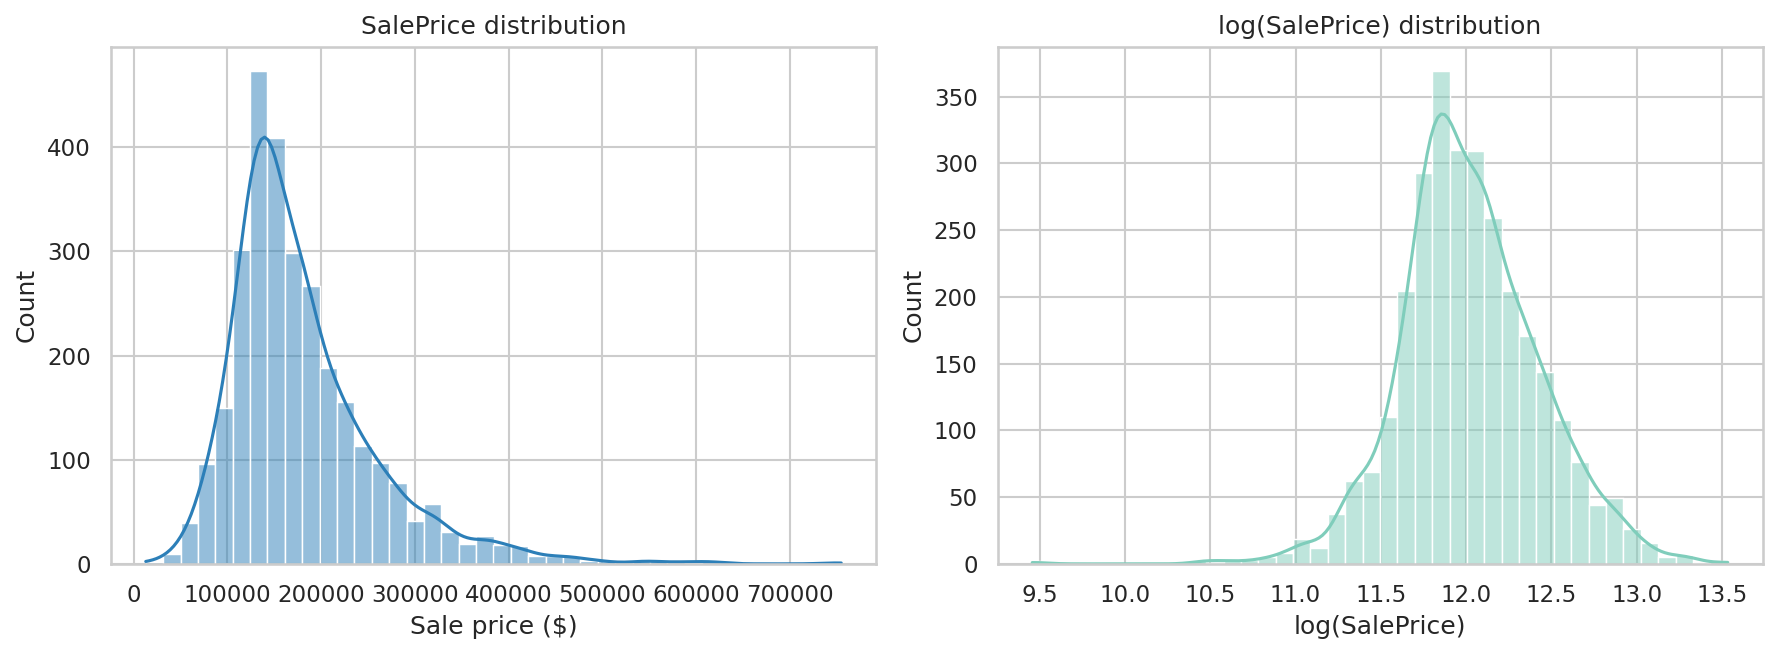

Skewness of SalePrice: 1.74
Skewness of log(SalePrice): -0.01
Median price: $ 160,000
Mean price:   $ 180,796


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df['SalePrice'], bins=40, kde=True, ax=axes[0], color='#2c7fb8')
axes[0].set_title('SalePrice distribution')
axes[0].set_xlabel('Sale price ($)')
sns.histplot(np.log1p(df['SalePrice']), bins=40, kde=True, ax=axes[1], color='#7fcdbb')
axes[1].set_title('log(SalePrice) distribution')
axes[1].set_xlabel('log(SalePrice)')
plt.tight_layout()
show_fig('price_distribution.png')

print('Skewness of SalePrice:', round(df['SalePrice'].skew(), 2))
print('Skewness of log(SalePrice):', round(np.log1p(df['SalePrice']).skew(), 2))
print('Median price: $', f"{df['SalePrice'].median():,.0f}")
print('Mean price:   $', f"{df['SalePrice'].mean():,.0f}")

### 4.2 What correlates most strongly with price?

In [8]:
corr = (df.corr(numeric_only=True)['SalePrice']
        .drop('SalePrice')
        .sort_values(ascending=False))
print(corr.head(15).round(3))

OverallQual      0.799
GrLivArea        0.707
GarageCars       0.648
GarageArea       0.640
TotalBsmtSF      0.633
1stFlrSF         0.622
YearBuilt        0.558
FullBath         0.546
GarageYrBlt      0.540
YearRemod/Add    0.533
MasVnrArea       0.502
TotRmsAbvGrd     0.495
Fireplaces       0.475
BsmtFinSF1       0.433
LotFrontage      0.353
Name: SalePrice, dtype: float64


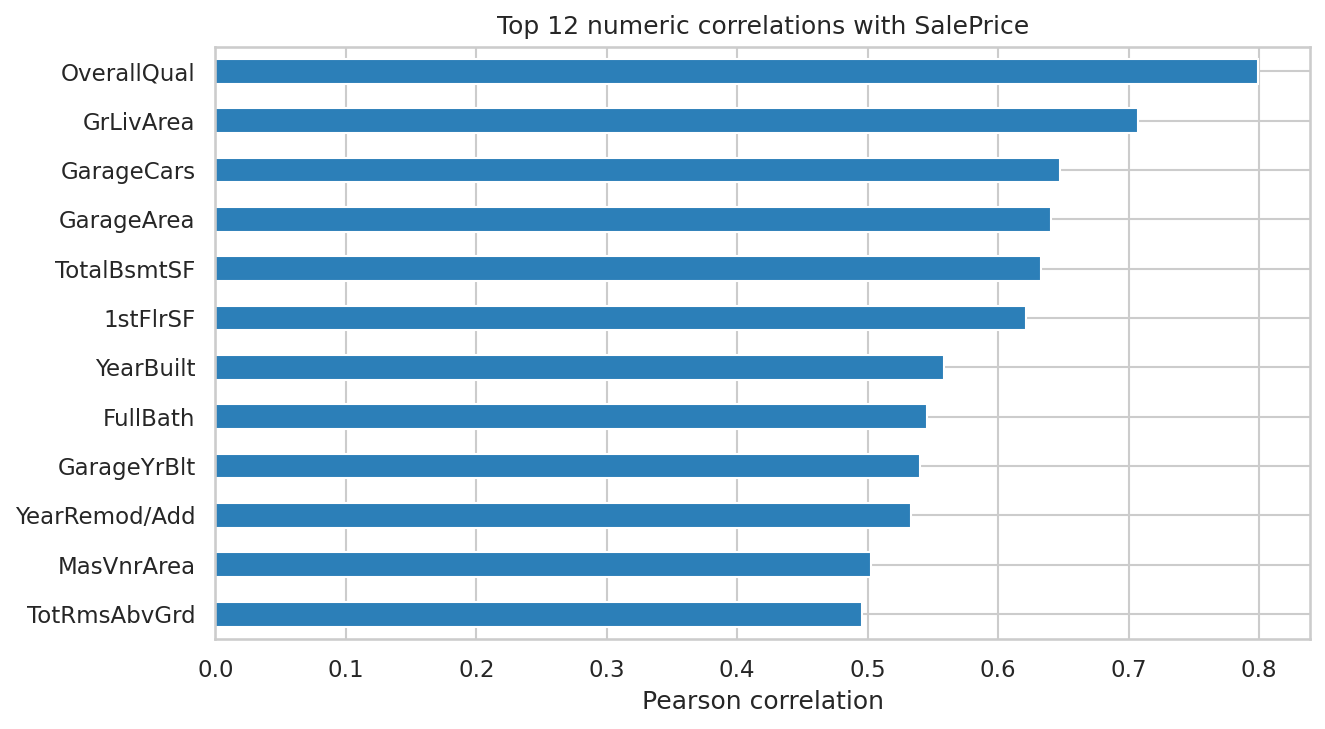

In [9]:
top_corr = corr.head(12)
fig, ax = plt.subplots(figsize=(9, 5))
top_corr.sort_values().plot.barh(ax=ax, color='#2c7fb8')
ax.set_title('Top 12 numeric correlations with SalePrice')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
show_fig('top_correlations.png')

### 4.3 Price by neighborhood

Location matters a great deal: median prices across the largest neighborhoods span roughly a twofold range.

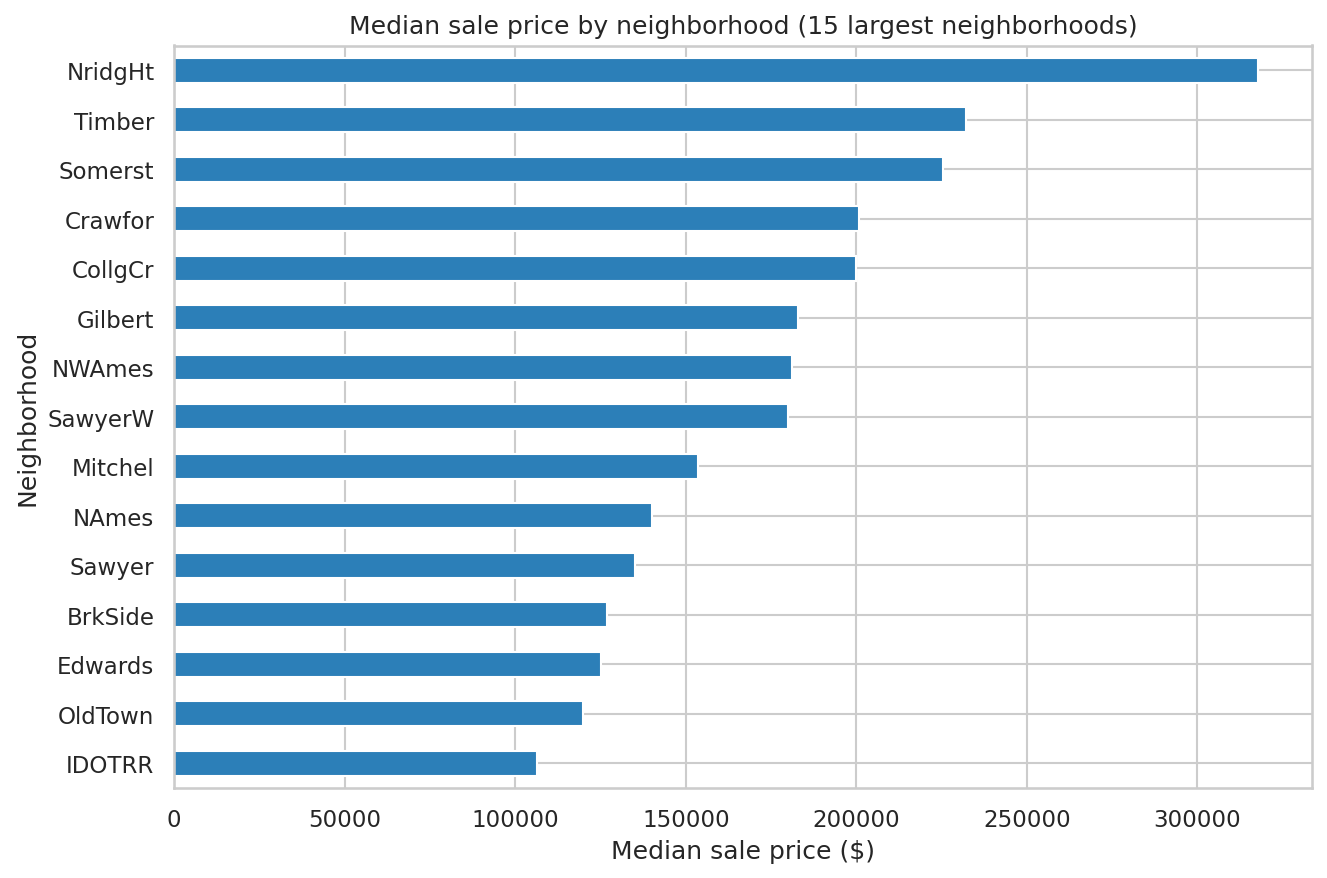

Neighborhood
IDOTRR     106500.0
OldTown    119900.0
Edwards    125000.0
BrkSide    126750.0
Sawyer     135000.0
NAmes      140000.0
Mitchel    153500.0
SawyerW    180000.0
NWAmes     181000.0
Gilbert    183000.0
CollgCr    200000.0
Crawfor    200624.0
Somerst    225500.0
Timber     232106.0
NridgHt    317750.0
Name: SalePrice, dtype: float64


In [10]:
top_nb = df['Neighborhood'].value_counts().head(15).index
med_price = (df[df['Neighborhood'].isin(top_nb)]
             .groupby('Neighborhood')['SalePrice'].median().sort_values())
fig, ax = plt.subplots(figsize=(9, 6))
med_price.plot.barh(ax=ax, color='#2c7fb8')
ax.set_title('Median sale price by neighborhood (15 largest neighborhoods)')
ax.set_xlabel('Median sale price ($)')
plt.tight_layout()
show_fig('price_by_neighborhood.png')
print(med_price.round(0))

### 4.4 Price by overall quality

`OverallQual` rates the material and finish of the house on a 1–10 scale. Median price rises steeply and monotonically with quality — quality is one of the strongest single predictors in the data.

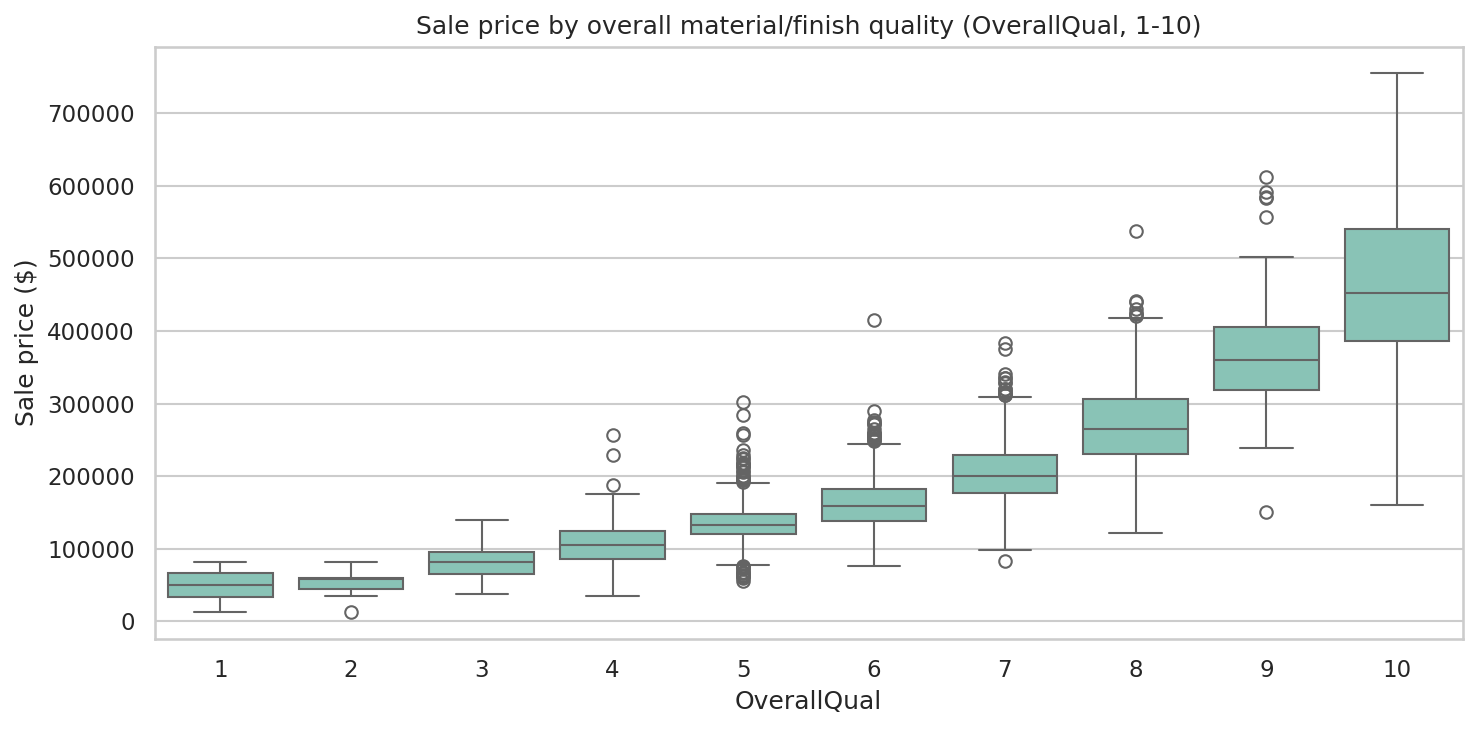

OverallQual
1      50150.0
2      57625.0
3      81200.0
4     105000.0
5     133000.0
6     159500.0
7     200000.0
8     264530.0
9     360000.0
10    451950.0
Name: SalePrice, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='OverallQual', y='SalePrice', ax=ax, color='#7fcdbb')
ax.set_title('Sale price by overall material/finish quality (OverallQual, 1-10)')
ax.set_xlabel('OverallQual')
ax.set_ylabel('Sale price ($)')
plt.tight_layout()
show_fig('price_by_quality.png')
print(df.groupby('OverallQual')['SalePrice'].median().round(0))

### 4.5 Living area vs price

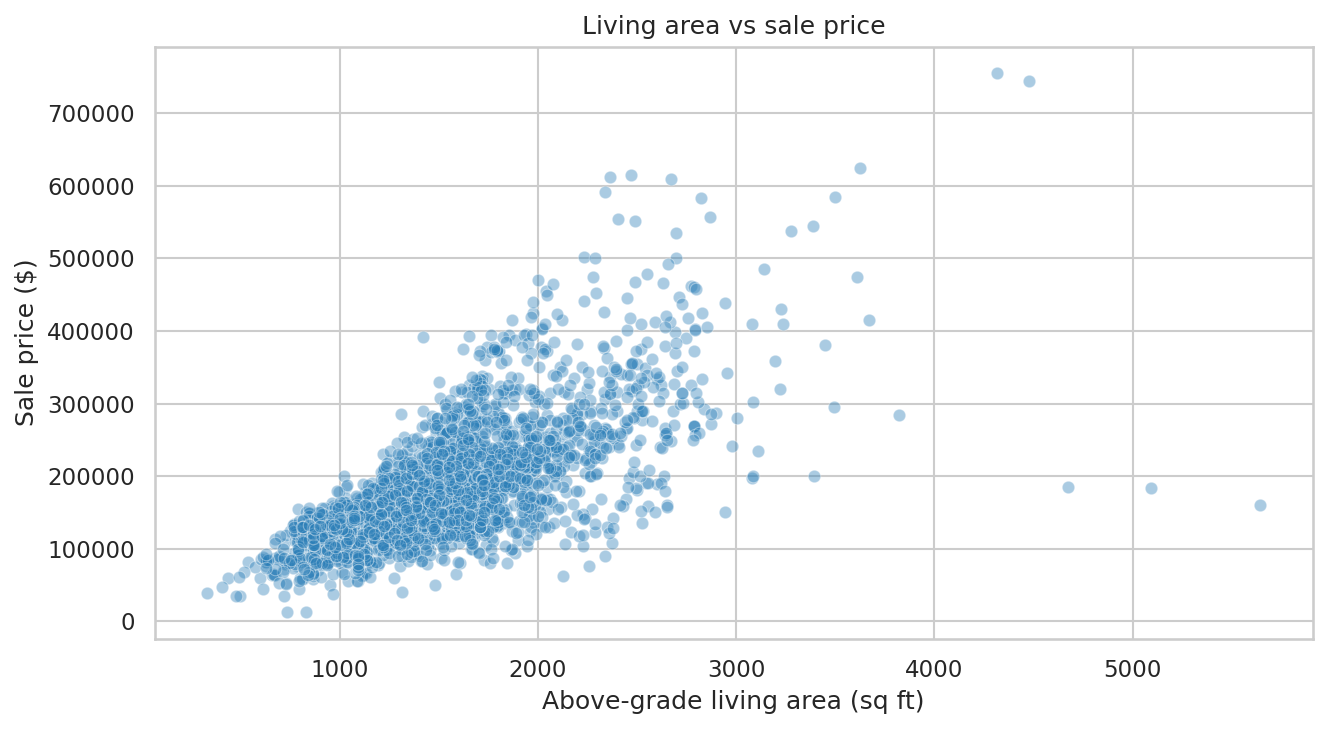

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', ax=ax, alpha=0.4, color='#2c7fb8')
ax.set_title('Living area vs sale price')
ax.set_xlabel('Above-grade living area (sq ft)')
ax.set_ylabel('Sale price ($)')
plt.tight_layout()
show_fig('living_area_vs_price.png')

### 4.6 Year built vs price

Newer homes tend to sell for more, but the relationship is not a straight line: the oldest homes (pre-1940) hold their value better than mid-century stock, and the premium is concentrated in homes built after about 1990.

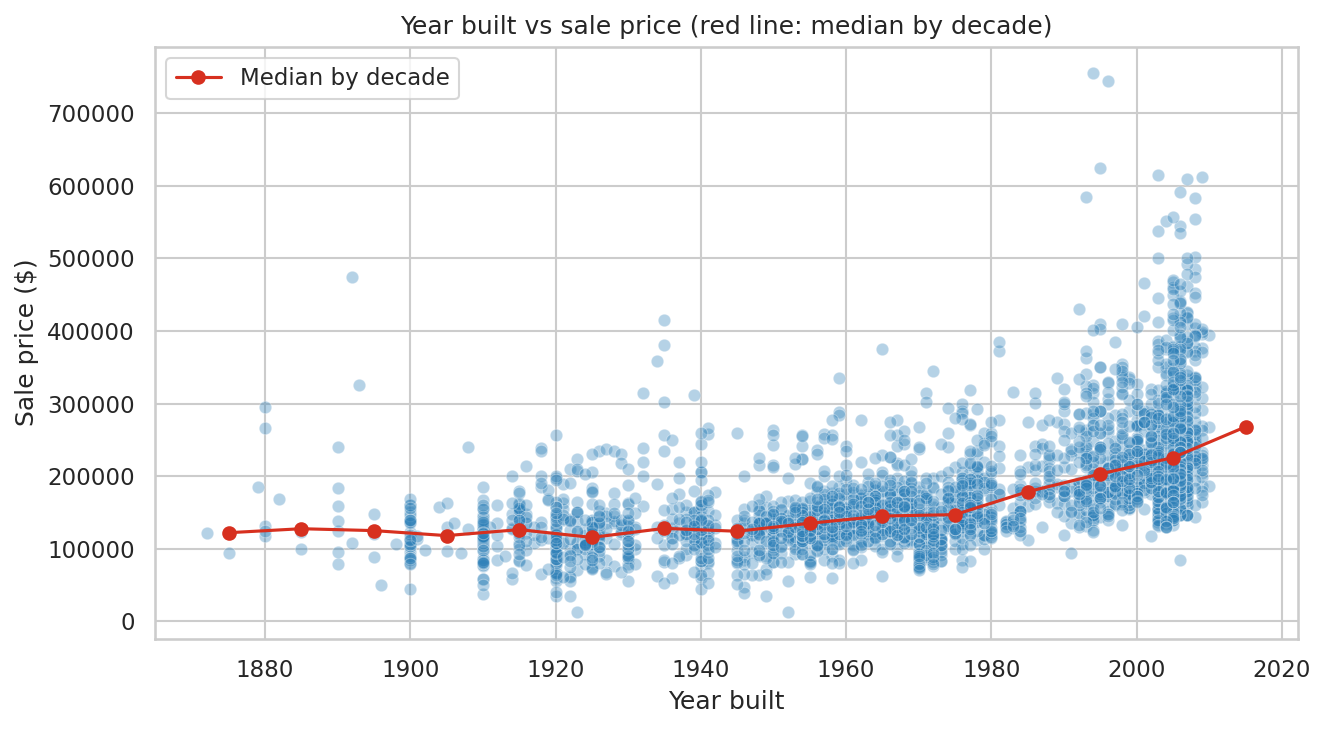

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice', ax=ax, alpha=0.35, color='#2c7fb8')
decade_med = (df.assign(Decade=(df['YearBuilt'] // 10 * 10))
              .groupby('Decade')['SalePrice'].median())
ax.plot(decade_med.index + 5, decade_med.values, color='#d7301f',
        marker='o', label='Median by decade')
ax.legend()
ax.set_title('Year built vs sale price (red line: median by decade)')
ax.set_xlabel('Year built')
ax.set_ylabel('Sale price ($)')
plt.tight_layout()
show_fig('year_built_vs_price.png')

## 5. Feature engineering

Six new features, each motivated by how buyers actually value a house:

| Feature | Definition | Why it should help |
|---|---|---|
| `HouseAge` | `YrSold - YearBuilt` | Age at sale is more directly meaningful than the raw build year. |
| `RemodAge` | `YrSold - YearRemod/Add` | A recently remodelled old house behaves more like a newer one. |
| `TotalLivingArea` | `1stFlrSF + 2ndFlrSF` | Total above-grade floor area in one number (differs from `GrLivArea` only by excluding low-quality finished space). |
| `TotalBath` | Full baths + 0.5 × half baths, above grade and basement | One bathroom count instead of four scattered columns. |
| `TotalPorchSF` | Open + enclosed + 3-season + screen porch + wood deck | Total outdoor living space. |
| `Qual_x_Area` | `OverallQual × GrLivArea` | **Interaction feature:** a large house is worth more when it is also well finished — quality and size multiply rather than add. |

In [14]:
df['HouseAge'] = df['YrSold'] - df['YearBuilt']
df['RemodAge'] = df['YrSold'] - df['YearRemod/Add']
df['TotalLivingArea'] = df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                   + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
df['TotalPorchSF'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch']
                      + df['ScreenPorch'] + df['WoodDeckSF'])
df['Qual_x_Area'] = df['OverallQual'] * df['GrLivArea']

new_features = ['HouseAge', 'RemodAge', 'TotalLivingArea', 'TotalBath',
                'TotalPorchSF', 'Qual_x_Area']
print(df[new_features].describe().round(1))
print()
print('Correlation of new features with SalePrice:')
print(df[new_features + ['SalePrice']].corr()['SalePrice']
      .drop('SalePrice').sort_values(ascending=False).round(3))

       HouseAge  RemodAge  TotalLivingArea  TotalBath  TotalPorchSF  Qual_x_Area
count    2930.0    2930.0           2930.0     2930.0        2930.0       2930.0
mean       36.4      23.5           1495.0        2.2         182.9       9547.3
std        30.3      20.9            503.1        0.8         159.8       4997.2
min        -1.0      -2.0            334.0        1.0           0.0        334.0
25%         7.0       4.0           1120.0        1.5          48.0       5917.0
50%        34.0      15.0           1440.0        2.0         165.0       8640.0
75%        54.0      42.8           1740.0        2.5         266.0      11966.8
max       136.0      60.0           5642.0        7.0        1424.0      56420.0

Correlation of new features with SalePrice:
Qual_x_Area        0.845
TotalLivingArea    0.714
TotalBath          0.636
TotalPorchSF       0.384
RemodAge          -0.535
HouseAge          -0.559
Name: SalePrice, dtype: float64


## 6. ANOVA — do prices really differ across groups?

The charts above suggest price varies by neighborhood, house style, and quality. One-way ANOVA tests whether those differences are statistically significant or could plausibly be chance. The test is run on log(price), because ANOVA assumes roughly normally distributed residuals and raw prices are heavily skewed.

Small groups are combined so every group has a reasonable sample size: the 10 largest neighborhoods (the other 18 become "Other"), the 4 most common house styles (the rest become "Other"), and quality grouped into bands (1–4, 5, 6, 7, 8, 9–10).

In [15]:
df['LogPrice'] = np.log1p(df['SalePrice'])

# Neighborhood: 10 largest neighborhoods, the rest grouped as "Other"
top10_nb = df['Neighborhood'].value_counts().head(10).index
df['NeighborhoodGroup'] = np.where(df['Neighborhood'].isin(top10_nb),
                                   df['Neighborhood'], 'Other')

# HouseStyle: the four most common styles, the rest grouped as "Other"
common_styles = ['1Story', '2Story', '1.5Fin', 'SLvl']
df['HouseStyleGroup'] = np.where(df['HouseStyle'].isin(common_styles),
                                 df['HouseStyle'], 'Other')

# OverallQual: grouped into bands so every group has a reasonable sample size
df['QualBand'] = pd.cut(df['OverallQual'], bins=[0, 4, 5, 6, 7, 8, 10],
                        labels=['1-4', '5', '6', '7', '8', '9-10'])

def run_anova(factor, label):
    model = ols(f'LogPrice ~ C({factor})', data=df).fit()
    table = sm.stats.anova_lm(model, typ=2)
    f_stat = float(table.loc[f'C({factor})', 'F'])
    p_val = float(table.loc[f'C({factor})', 'PR(>F)'])
    print(f'--- {label} ---')
    print(table.round(3))
    print(f'F = {f_stat:,.1f}, p = {p_val:.3g}\n')
    return f_stat, p_val

nb_f, nb_p = run_anova('NeighborhoodGroup', 'Sale price by neighborhood group')
hs_f, hs_p = run_anova('HouseStyleGroup', 'Sale price by house style group')
qb_f, qb_p = run_anova('QualBand', 'Sale price by overall quality band')

--- Sale price by neighborhood group ---
                       sum_sq      df        F  PR(>F)
C(NeighborhoodGroup)  154.152    10.0  135.359     0.0
Residual              332.427  2919.0      NaN     NaN
F = 135.4, p = 6.32e-233

--- Sale price by house style group ---
                     sum_sq      df       F  PR(>F)
C(HouseStyleGroup)   39.891     4.0  65.304     0.0
Residual            446.688  2925.0     NaN     NaN
F = 65.3, p = 5.64e-53



--- Sale price by overall quality band ---
              sum_sq      df         F  PR(>F)
C(QualBand)  323.228     5.0  1157.158     0.0
Residual     163.352  2924.0       NaN     NaN
F = 1,157.2, p = 0



### Interpreting the ANOVA results

All three factors show statistically significant differences in (log) sale price:

- **Neighborhood:** F = 135.4, p < 0.001 — significant. Where a house sits in Ames matters: the most expensive neighborhoods sell for far more than the cheapest, and the gap is far too large to be chance.
- **House style:** F = 65.3, p < 0.001 — significant. Two-storey homes, for example, sell at different prices than one-storey homes on average, though style is a weaker separator than neighborhood or quality.
- **Overall quality:** F = 1,157.2, p < 0.001 — significant. Quality is the strongest group separator of the three: the median price rises from $133,000 for a quality-5 home to $451,950 for a quality-10 home.

In plain terms: location, house style, and especially build quality all genuinely move house prices in Ames — these are real differences, not sampling noise. (ANOVA tests whether group averages differ; it does not by itself say *why* — quality and neighborhood are also correlated with size and age, which the regression models in the next section account for.)

## 7. Modelling

**Setup:** 80/20 train/test split (`random_state=42`). The target is log(price); all reported errors are converted back to dollars. Numeric features are median-imputed and standardized; categorical features are most-frequent-imputed and one-hot encoded — all inside `Pipeline`s so no information leaks from the test set. `MSSubClass` is a dwelling-type code, not a quantity, so it is treated as categorical.

**Models:** Linear Regression (baseline), Ridge, Random Forest and XGBoost — the two tree models tuned with `RandomizedSearchCV` (12 candidates, 3-fold CV).

In [16]:
X = df.drop(columns=['SalePrice', 'LogPrice', 'NeighborhoodGroup',
                     'HouseStyleGroup', 'QualBand'])
y = np.log1p(df['SalePrice'])

# MSSubClass is a dwelling-type code, not a quantity - treat it as categorical
X['MSSubClass'] = X['MSSubClass'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
print(f'{len(num_cols)} numeric features, {len(cat_cols)} categorical features')

Train: (2344, 83), Test: (586, 83)
41 numeric features, 42 categorical features


In [17]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols),
])

def evaluate(model, name):
    pred = np.expm1(model.predict(X_test))
    actual = np.expm1(y_test)
    return {
        'Model': name,
        'RMSE ($)': round(float(root_mean_squared_error(actual, pred)), 0),
        'MAE ($)': round(float(mean_absolute_error(actual, pred)), 0),
        'R2': round(float(r2_score(actual, pred)), 3),
    }

results = []

### 7.1 Baseline: Linear Regression and Ridge

In [18]:
lr = Pipeline([('preprocess', preprocessor),
               ('model', LinearRegression())])
lr.fit(X_train, y_train)
results.append(evaluate(lr, 'Linear Regression'))

ridge = Pipeline([('preprocess', preprocessor),
                  ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
ridge.fit(X_train, y_train)
results.append(evaluate(ridge, 'Ridge (alpha=1)'))

print('Linear Regression and Ridge fitted.')

Linear Regression and Ridge fitted.


### 7.2 Random Forest with hyperparameter tuning

In [19]:
rf_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt', 0.6],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=10, cv=3,
                               scoring='neg_root_mean_squared_error',
                               random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)
print('Best Random Forest params:', rf_search.best_params_)
rf_best = rf_search.best_estimator_
results.append(evaluate(rf_best, 'Random Forest (tuned)'))

Best Random Forest params: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.6, 'model__max_depth': 20}


### 7.3 XGBoost with hyperparameter tuning

In [20]:
xgb_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1,
                           tree_method='hist')),
])
xgb_grid = {
    'model__n_estimators': [300, 500],
    'model__max_depth': [3, 4, 6],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.7, 1.0],
    'model__reg_lambda': [1, 5],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_grid, n_iter=10, cv=3,
                                scoring='neg_root_mean_squared_error',
                                random_state=RANDOM_STATE, n_jobs=-1)
xgb_search.fit(X_train, y_train)
print('Best XGBoost params:', xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_
results.append(evaluate(xgb_best, 'XGBoost (tuned)'))

Best XGBoost params: {'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 500, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}


### 7.4 Model comparison (test set, original dollar scale)

In [21]:
results_df = pd.DataFrame(results).sort_values('RMSE ($)').reset_index(drop=True)
results_df

,Model,RMSE ($),MAE ($),R2
0,XGBoost (tuned),22047.0,13468.0,0.939
1,Random Forest (tuned),25975.0,15231.0,0.916
2,Ridge (alpha=1),27820.0,15413.0,0.903
3,Linear Regression,28737.0,15069.0,0.897


### 7.5 What the best tree model relies on

Best tree model: XGBoost
num__Qual_x_Area             0.127
num__OverallQual             0.049
cat__CentralAir_N            0.045
cat__ExterQual_TA            0.044
cat__CentralAir_Y            0.032
num__GarageCars              0.029
cat__Neighborhood_OldTown    0.027
num__Fireplaces              0.026
cat__MSZoning_RM             0.024
cat__PavedDrive_Y            0.024
cat__PavedDrive_N            0.023
cat__BsmtQual_Ex             0.023
num__TotalBath               0.021
cat__GarageType_Attchd       0.021
num__HouseAge                0.019
dtype: float32


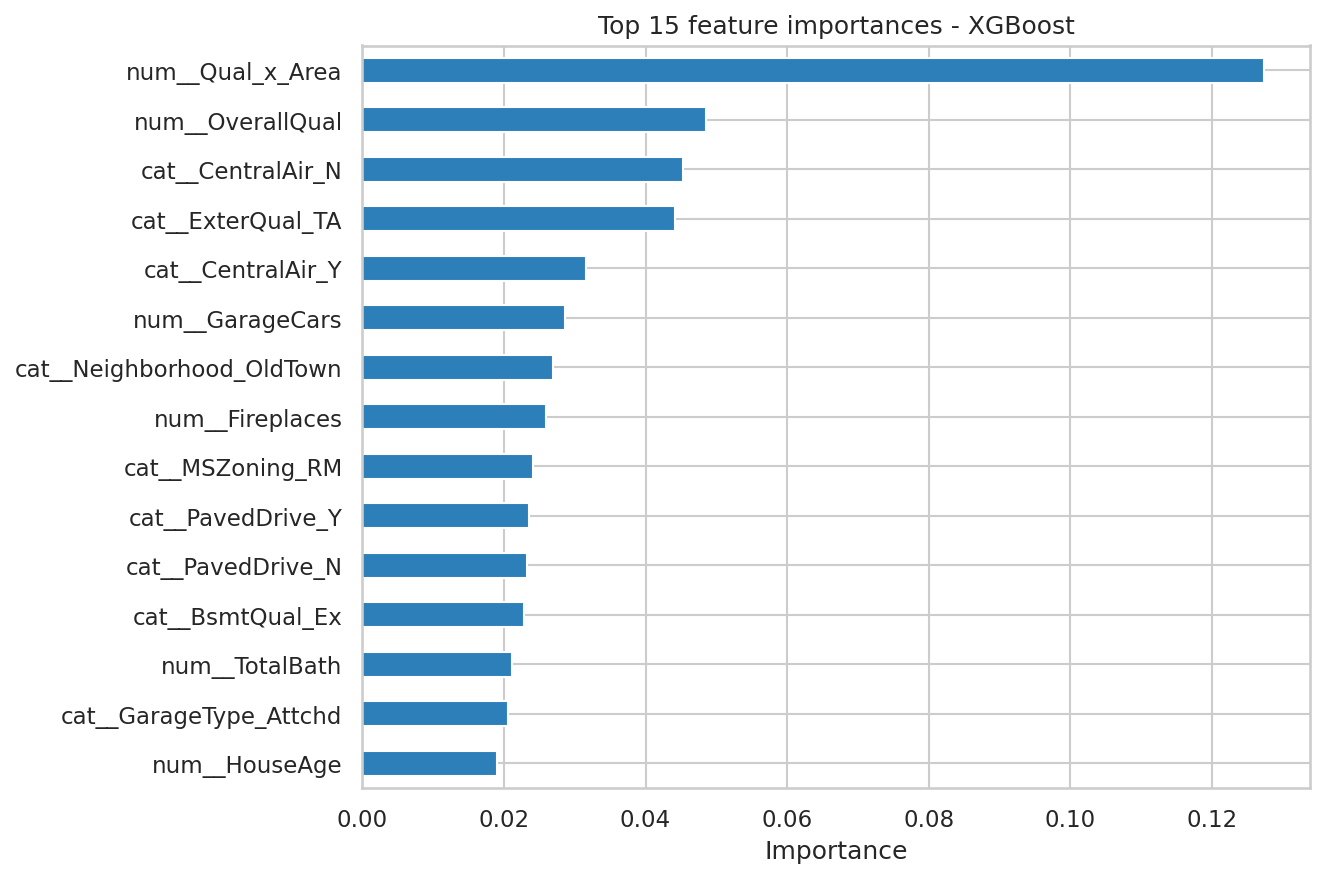

In [22]:
rf_rmse = results_df.loc[results_df['Model'] == 'Random Forest (tuned)', 'RMSE ($)'].iloc[0]
xgb_rmse = results_df.loc[results_df['Model'] == 'XGBoost (tuned)', 'RMSE ($)'].iloc[0]
best_tree, best_tree_name = ((xgb_best, 'XGBoost') if xgb_rmse <= rf_rmse
                             else (rf_best, 'Random Forest'))
print(f'Best tree model: {best_tree_name}')

importances = best_tree.named_steps['model'].feature_importances_
feature_names = best_tree.named_steps['preprocess'].get_feature_names_out()
imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(imp.head(15).round(3))

top15 = imp.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
top15.plot.barh(ax=ax, color='#2c7fb8')
ax.set_title(f'Top 15 feature importances - {best_tree_name}')
ax.set_xlabel('Importance')
plt.tight_layout()
show_fig('feature_importance.png')

### 7.6 Predicted vs actual for the best model

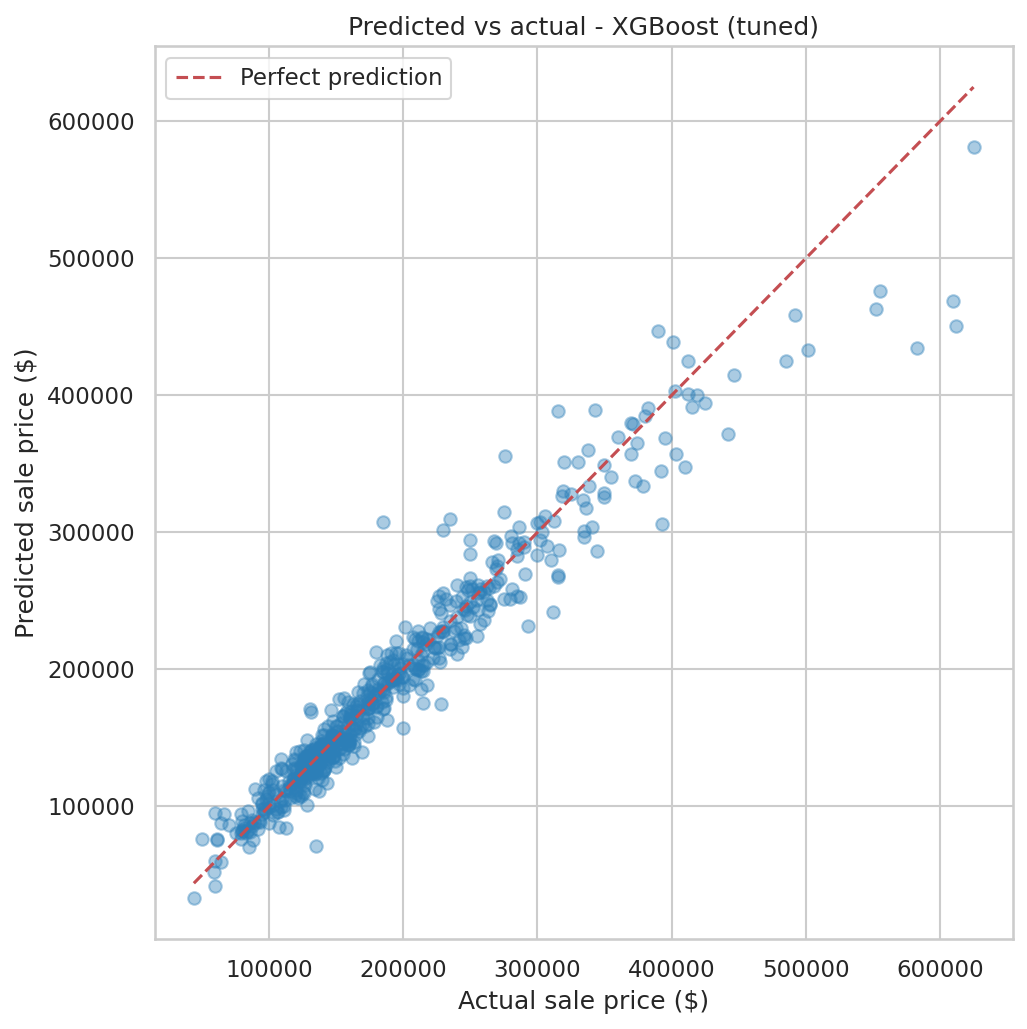

In [23]:
best_name = results_df.iloc[0]['Model']
models = {'Linear Regression': lr, 'Ridge (alpha=1)': ridge,
          'Random Forest (tuned)': rf_best, 'XGBoost (tuned)': xgb_best}
best_model = models[best_name]
pred = np.expm1(best_model.predict(X_test))
actual = np.expm1(y_test)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(actual, pred, alpha=0.4, color='#2c7fb8')
ax.plot([actual.min(), actual.max()], [actual.min(), actual.max()],
        'r--', label='Perfect prediction')
ax.set_xlabel('Actual sale price ($)')
ax.set_ylabel('Predicted sale price ($)')
ax.set_title(f'Predicted vs actual - {best_name}')
ax.legend()
plt.tight_layout()
show_fig('predicted_vs_actual.png')

### 7.7 Save the run summary

Key numbers from this run are saved to `results_summary.json` so the README and findings can quote them exactly.

In [24]:
def _jsonable(v):
    return v.item() if hasattr(v, 'item') else v

nb_median = df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False)
qual_median = df.groupby('OverallQual')['SalePrice'].median()

summary = {
    'n_rows': int(len(df)),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'median_price': float(df['SalePrice'].median()),
    'mean_price': float(df['SalePrice'].mean()),
    'price_skew': float(df['SalePrice'].skew()),
    'log_price_skew': float(np.log1p(df['SalePrice']).skew()),
    'top_correlations': {k: round(float(v), 3)
                         for k, v in corr.head(5).items()},
    'new_feature_corr': {k: round(float(v), 3) for k, v in
                         df[new_features + ['SalePrice']].corr()['SalePrice']
                         .drop('SalePrice').items()},
    'neighborhood_top3': {k: round(float(v), 0)
                          for k, v in nb_median.head(3).items()},
    'neighborhood_bottom3': {k: round(float(v), 0)
                             for k, v in nb_median.tail(3).items()},
    'median_price_qual5': float(qual_median.loc[5]),
    'median_price_qual10': float(qual_median.loc[10]),
    'anova': {
        'neighborhood': {'F': nb_f, 'p': nb_p},
        'house_style': {'F': hs_f, 'p': hs_p},
        'overall_qual': {'F': qb_f, 'p': qb_p},
    },
    'results': [{k: _jsonable(v) for k, v in row.items()}
                for row in results_df.to_dict(orient='records')],
    'best_model': best_name,
    'best_tree_model': best_tree_name,
    'best_params_rf': {k: _jsonable(v) for k, v in rf_search.best_params_.items()},
    'best_params_xgb': {k: _jsonable(v) for k, v in xgb_search.best_params_.items()},
    'top_features': {k: round(float(v), 3) for k, v in imp.head(10).items()},
}
with open('results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved results_summary.json')
print('Best model:', best_name)

Saved results_summary.json
Best model: XGBoost (tuned)


## 8. Findings

### What drives house prices in Ames?

- **Quality and size dominate.** The strongest single correlates of sale price are OverallQual (r = 0.799), GrLivArea (r = 0.707), and GarageCars (r = 0.648). The median price of a quality-10 home ($451,950) is roughly 3.4x the median of a quality-5 home ($133,000).
- **Location matters.** Median prices range from $88,250 in MeadowV to $319,000 in StoneBr — and the ANOVA test confirms these neighborhood differences are statistically significant (F = 135.4, p < 0.001).
- **Age cuts both ways.** Newer homes command a premium, but the oldest pre-1940 homes hold value better than mid-century stock, and a recent remodel closes much of the age gap.
- **The engineered features helped.** The quality × living-area interaction (0.84 correlation with price) and total living area (0.71) rank among the strongest predictors, showing that quality and size multiply rather than simply add.

### How well can we predict price?

The best model, **XGBoost (tuned)**, predicts the sale price of a held-out home with a **test RMSE of $22,047** and a **mean absolute error of $13,468**, explaining **R² = 0.939** of the variation in prices. That is a 23% lower RMSE than the plain Linear Regression baseline ($28,737). In plain terms: for a typical $160,000 (median-price) home, the model's prediction is typically within about $13,468 of the actual sale price.

The XGBoost model relies most on **Qual_x_Area**, **OverallQual**, and **CentralAir = N** — the same quality, size, and location story the exploratory analysis told.

### Caveats

- The data covers one city (Ames, Iowa) and one period (2006–2010, spanning the housing downturn), so the exact price levels do not transfer to other markets.
- A handful of very expensive homes are still under-predicted (visible in the predicted-vs-actual chart) — the model is most reliable for typical homes near the median.
- ANOVA and correlations describe associations, not causes: quality, size, age, and neighborhood move together, so no single number here is the "effect" of changing one feature in isolation.